# Probabilistic Roadmap Method

Jonas Frei, 27.06.2024

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

## Hilfsfunktionen

Im Original stehen diese Funktionen am Ende des Skripts. Da Jupyter-Zellen der Reihe nach ausgeführt werden, stehen sie hier vor ihrer ersten Verwendung. Die Kollisionsprüfungen sind zudem mit NumPy vektorisiert statt elementweise in einer Schleife zu prüfen, da sonst allein der Aufbau der Roadmap sehr lange dauern würde.

Funktion um zu Überprüfen, ob ein Knoten mit einem Hindernis kollidiert

In [ ]:
def is_collision(point, obstacles):
    x, y = point
    inside = ((x >= obstacles[:, 0]) & (x <= obstacles[:, 0] + obstacles[:, 2])
              & (y >= obstacles[:, 1]) & (y <= obstacles[:, 1] + obstacles[:, 3]))
    return bool(inside.any())

Funktion um zu Überprüfen, ob eine Verbindung mit einem Hindernis kollidiert

In [ ]:
def is_segment_collision(p1, p2, obstacles, maxDist):
    numPoints = int(maxDist*20)
    x = np.linspace(p1[0], p2[0], numPoints)
    y = np.linspace(p1[1], p2[1], numPoints)
    inside = ((x[:, None] >= obstacles[None, :, 0]) & (x[:, None] <= obstacles[None, :, 0] + obstacles[None, :, 2])
              & (y[:, None] >= obstacles[None, :, 1]) & (y[:, None] <= obstacles[None, :, 1] + obstacles[None, :, 3]))
    return bool(inside.any())

Funktion zum Finden des nächstgelegenen Knoten

In [ ]:
def find_closest_node(point, nodes, obstacles, maxDist):
    distances = np.linalg.norm(nodes - point, axis=1)
    idx = int(np.argmin(distances))
    while is_segment_collision(point, nodes[idx], obstacles, maxDist):
        distances[idx] = np.inf
        idx = int(np.argmin(distances))
    return idx

Dijkstra-Algorithmus

In [ ]:
def dijkstra(adjMatrix, startNode, goalNode):
    n = adjMatrix.shape[0]
    dist = np.full(n, np.inf)
    prev = np.full(n, -1, dtype=int)
    dist[startNode] = 0
    visited = np.zeros(n, dtype=bool)
    unvisited = list(range(n))

    while unvisited:
        # Finde den unbesuchten Knoten mit der kleinsten Distanz
        idx = int(np.argmin([dist[u] for u in unvisited]))
        u = unvisited.pop(idx)

        if u == goalNode:
            break

        # Für jeden benachbarten Knoten
        for v in range(n):
            if adjMatrix[u, v] < np.inf and not visited[v]:
                alt = dist[u] + adjMatrix[u, v]
                if alt < dist[v]:
                    dist[v] = alt
                    prev[v] = u

        visited[u] = True

    # Rekonstruiere den Pfad vom Start- zum Zielknoten
    path = [goalNode]
    while prev[path[0]] != -1:
        path.insert(0, prev[path[0]])
    return path

## Parameterdefinition

Anzahl Knoten

In [ ]:
numNodes = 100

Maximale Verbindungsdistanz

In [ ]:
maxDist = 100

Kartengrösse

In [ ]:
xRange = [0, 100]
yRange = [0, 100]

Hindernisse als Vierecke [x, y, width, height]

In [ ]:
obstacles = np.array([
    [0, 0, 100, 1],
    [0, 0, 1, 100],
    [0, 99, 100, 1],
    [99, 0, 1, 100],
    [0, 80, 30, 1],
    [40, 60, 1, 40],
    [40, 0, 1, 39],
    [50, 80, 50, 1],
    [0, 49, 40, 1],
    [60, 10, 1, 40],
    [60, 60, 1, 20],
    [60, 50, 40, 1],
], dtype=float)

## Visualisierung

Gitterkarte mit Hindernissen

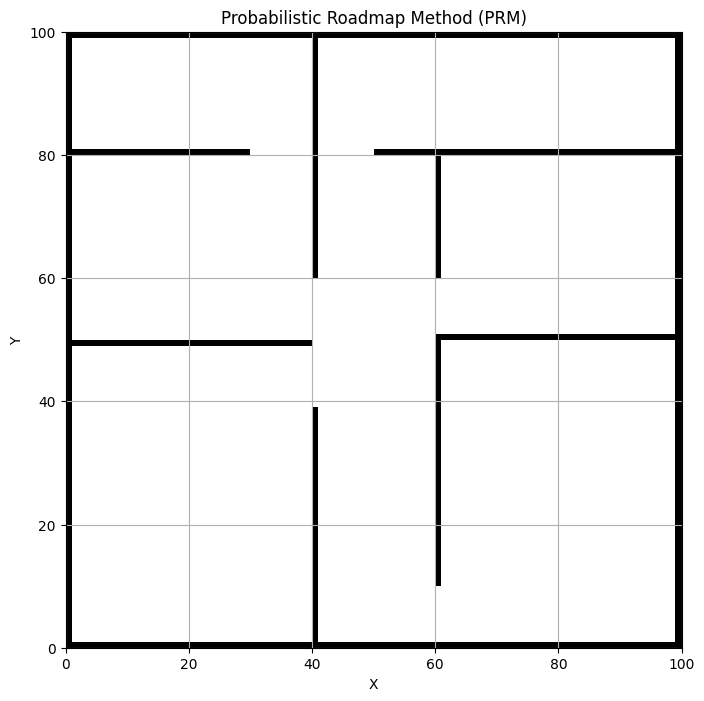

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(xRange)
ax.set_ylim(yRange)
ax.set_aspect('equal')
ax.set_title("Probabilistic Roadmap Method (PRM)")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.grid(True)

for obstacle in obstacles:
    ax.add_patch(Rectangle((obstacle[0], obstacle[1]), obstacle[2], obstacle[3], facecolor='black'))

Knoten, zufällig innerhalb der Gitterkarte wählen

In [ ]:
nodes = np.zeros((numNodes, 2))
validNodes = 0
while validNodes < numNodes:
    sample = np.array([np.random.rand()*(xRange[1] - xRange[0]) + xRange[0],
                        np.random.rand()*(yRange[1] - yRange[0]) + yRange[0]])
    if not is_collision(sample, obstacles):
        nodes[validNodes] = sample
        validNodes += 1
        ax.plot(sample[0], sample[1], 'ro')

Distanzmatrix zum Abspeichern der Distanzen zwischen den einzelnen Knoten initialisieren

In [ ]:
distanceMatrix = np.full((numNodes, numNodes), np.inf)

Verbindung der regulären Knoten und Abspeichern der Distanzen

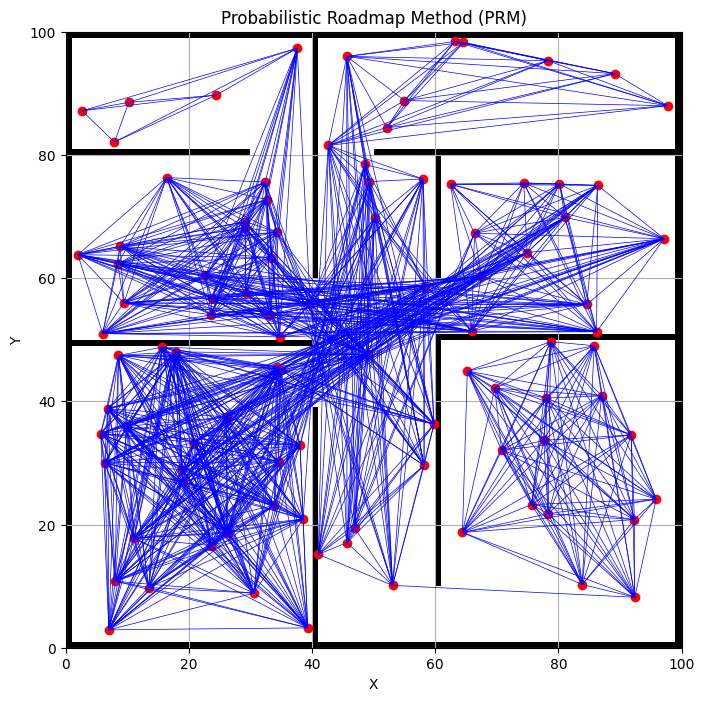

In [ ]:
edges = []
for i in range(numNodes):
    for j in range(i + 1, numNodes):
        d = np.linalg.norm(nodes[i] - nodes[j])
        if d <= maxDist and not is_segment_collision(nodes[i], nodes[j], obstacles, maxDist):
            edges.append((i, j))
            distanceMatrix[i, j] = d
            distanceMatrix[j, i] = d
            ax.plot([nodes[i, 0], nodes[j, 0]], [nodes[i, 1], nodes[j, 1]], 'b', linewidth=0.5)

fig

## Suchen des kürzesten Pfades mittels Dijkstra-Algorithmus

Das Original löscht hier zunächst bereits eingezeichnete Start-, Ziel- und Pfadmarkierungen (`Tag','path'`), um den Abschnitt mehrfach mit unterschiedlichen Start-/Zielpunkten ausführen zu können, ohne dass sich alte Markierungen ansammeln. Da dieses Notebook einmalig von oben nach unten durchläuft, entfällt dieser Schritt -- es gibt noch nichts zu löschen.

Startpunkt

In [ ]:
startNode = np.array([5., 5.])

Zielpunkt

In [ ]:
goalNode = np.array([95., 95.])

Start- und Zielpunkt plotten

In [ ]:
ax.plot(startNode[0], startNode[1], 'go', markersize=8, markerfacecolor='g', label="Start")
ax.plot(goalNode[0], goalNode[1], 'ro', markersize=8, markerfacecolor='r', label="Ziel")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))

Start- und Zielpunkt nur mit nächstem Knoten verbinden

In [ ]:
startIdx = find_closest_node(startNode, nodes, obstacles, maxDist)
goalIdx = find_closest_node(goalNode, nodes, obstacles, maxDist)

ax.plot([startNode[0], nodes[startIdx, 0]], [startNode[1], nodes[startIdx, 1]], 'g', linewidth=2)
ax.plot([goalNode[0], nodes[goalIdx, 0]], [goalNode[1], nodes[goalIdx, 1]], 'r', linewidth=2)

Kürzesten Pfad mittels Dijkstra suchen

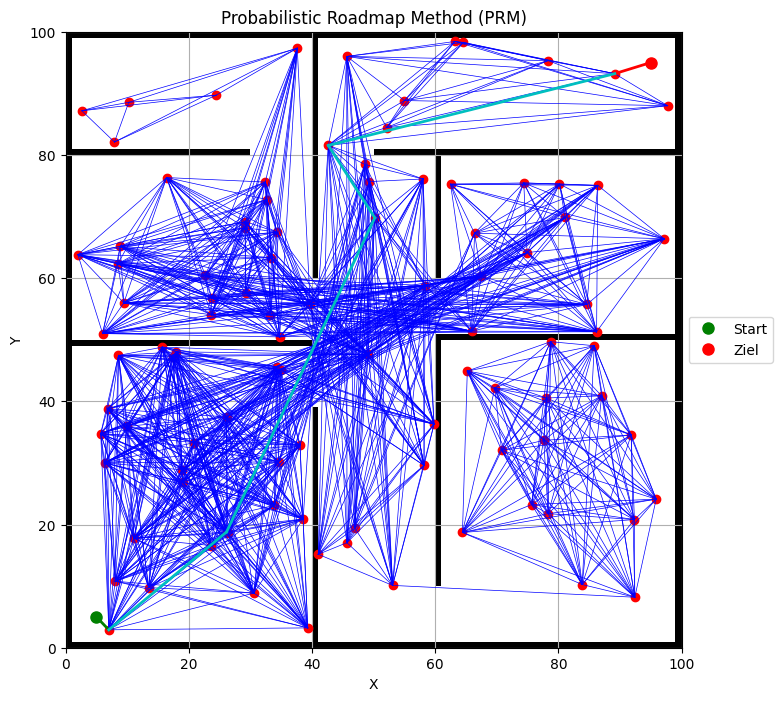

In [ ]:
path = dijkstra(distanceMatrix, startIdx, goalIdx)
for i in range(len(path) - 1):
    ax.plot([nodes[path[i], 0], nodes[path[i + 1], 0]],
            [nodes[path[i], 1], nodes[path[i + 1], 1]], 'c', linewidth=2)

fig